# Project 3. Part 1 - CLD Aggregation Tool

Last update: 05/23/2024

Title: Streamlining the Aggregation of Causal Loop Diagrams: A Thematic Labeling and Adjacency Matrix Approach

Overview: 
Spaghetti Causal Loop Diagrams (CLDs) present a significant challenge for modelers in effectively communicating complex system dynamics to stakeholders. Traditionally, modelers manually synthesize multiple CLDs to create an aggregated diagram that provides a higher-level understanding of the system. This paper introduces a streamlined procedure for aggregating CLDs using general categorical labels. 

The methodology involves translating qualitative mental models into adjacency matrices that capture both links and polarity signs, manually coding and substituting variable names with thematic labels, aggregating these matrices to identify significant feedback loops, and validating the approach by comparing it with the manual synthesis performed by an expert system dynamicist. 

Our results demonstrate that this tool is highly useful for group model-building experts, particularly when dealing with a large number of mental maps. The proposed method enhances the clarity and efficiency of synthesizing complex CLDs, thereby improving the overall communication of system dynamics.







In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import os 
import pickle
import pandas as pd
import sys
import networkx as nx
import matplotlib.pyplot as plt
import gravis as gv

# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

import parse_cld
import cld_nx
import data_io


In [4]:
# Set the new directory
new_dir = "/Users/gl665/PycharmProjects/Phrame_MentalMaps"
# Change the current working directory
os.chdir(new_dir)

print(os.getcwd())

/Users/gl665/PycharmProjects/Phrame_MentalMaps


In [5]:
# Read all the json files in 
my_data_RC = {}
folder_path = 'results/SYNCH/JSON_file/RC/'

my_data_RC = data_io.read_json(folder_path, my_data_RC)

results/SYNCH/JSON_file/RC/FM 51220Clean.json
load: FM 51220Clean.json
results/SYNCH/JSON_file/RC/Passages Clean.json
load: Passages Clean.json
results/SYNCH/JSON_file/RC/full circle GBM 5 24 21clean.json
load: full circle GBM 5 24 21clean.json
results/SYNCH/JSON_file/RC/C 7 6 20 clean model.json
load: C 7 6 20 clean model.json
results/SYNCH/JSON_file/RC/Wavi combined clean.json
load: Wavi combined clean.json
results/SYNCH/JSON_file/RC/drug justice model clean.json
load: drug justice model clean.json
results/SYNCH/JSON_file/RC/DSS23.json
load: DSS23.json
results/SYNCH/JSON_file/RC/E clean model 572020.json
load: E clean model 572020.json
results/SYNCH/JSON_file/RC/nat model clean2.json
load: nat model clean2.json
results/SYNCH/JSON_file/RC/FC Prov Clean.json
load: FC Prov Clean.json
results/SYNCH/JSON_file/RC/full circle clean.json
load: full circle clean.json
results/SYNCH/JSON_file/RC/reentry clean model.json
load: reentry clean model.json
results/SYNCH/JSON_file/RC/DV justice model 

In [6]:
file_rename = pd.read_excel('results/SYNCH/file_rename/RC_file_rename.xlsx', index_col=0)
file_rename['file_no.'] = [i+1 for i in range(len(file_rename.index))]
file_rename.head(3)

dict_file_rename = dict(zip(file_rename['Filename'], file_rename['Model Name']))
dict_file_rename

{'FM 51220Clean.json': 'FM',
 'Passages Clean.json': 'PA',
 'full circle GBM 5 24 21clean.json': 'FullGMB',
 'C 7 6 20 clean model.json': 'C76',
 'tracy clean model.json': 'Tracy',
 'Wavi combined clean.json': 'Wavi',
 'drug justice model clean.json': 'JUSTICE',
 '7 13 20 clean model.json': 'C713',
 'DSS23.json': 'DSS',
 'E clean model 572020.json': 'E',
 'nat model clean2.json': 'NAT',
 'j model 7 13 20 clean model3.json': 'J713',
 'FC Prov Clean.json': 'FC',
 'full circle clean.json': 'Full',
 'reentry clean model.json': 'Reentry',
 '1 6 21 Legal clean.json': 'Legal',
 'DV justice model clean.json': 'DV',
 'SOC clean.json': 'SOC',
 'RC 4 28 2021 Clean.json': 'RC'}

In [106]:
# preprocess the RC_Updated_Themes.xslx and match it back with the RC files. 
# df_rc_themes = pd.read_excel('Dataset/SYNCH/aggregate_theme/RC_Updated_Themes.xlsx', sheet_name= "clean")

# # get column 1 and 4
# df_aggregate_names = df_rc_themes.iloc[:, [1, 4]]

# df_aggregate_names.columns = ['theme', 'variable']
# # delete rows if both are column values are nan 
# df_aggregate_names = df_aggregate_names.dropna(subset=['theme', 'variable'], how='all')


# df_aggregate_names['theme'] = df_aggregate_names['theme'].fillna(method='ffill')
# df_aggregate_names['theme']= df_aggregate_names['theme'].str.lower()
# df_aggregate_names['variable']= df_aggregate_names['variable'].str.lower()

# df_aggregate_names.head(20)
# df_aggregate_names.to_csv('Dataset/SYNCH/aggregate_theme/RC_theme_var_matching.csv', index=False)

In [7]:
df_aggregate_names = pd.read_csv('data/SYNCH/aggregate_theme/RC_theme_var_matching.csv')
unique_theme_names = set(df_aggregate_names['theme'])
df_aggregate_names.head()


,theme,variable
0,healthy development,child psychological development
1,healthy development,healthy child development
2,healthy development,child behavioral issues
3,healthy development,child physcial violent perpetration
4,healthy development,developmental delay in child


## Merging Network X graphs

### Merging by using adjacency matrix

In [110]:
dict_pol_mx = {}
dict_adj_mx = {}
for key, value in my_data_RC.items():
    print(key)
    merge_df,  theme_dict = parse_cld.get_theme_cld(value, df_aggregate_names)
    adj_mx = parse_cld.get_aggregate_adjacency_mx(merge_df,  theme_dict)
    dict_adj_mx[key] = adj_mx

    pol_mx = parse_cld.get_aggregate_polarity_mx (merge_df, theme_dict)
    # print(pol_mx.shape)
    dict_pol_mx[key] = pol_mx 


FM 51220Clean.json
Passages Clean.json
full circle GBM 5 24 21clean.json
C 7 6 20 clean model.json
Wavi combined clean.json
drug justice model clean.json
DSS23.json
E clean model 572020.json
nat model clean2.json
FC Prov Clean.json
full circle clean.json
reentry clean model.json
DV justice model clean.json


In [103]:
# df_theme_dict = pd.DataFrame.from_dict(theme_dict, orient='index')
# df_theme_dict
# df_theme_dict.to_csv("theme_dict.csv")

In [111]:
# get the aggregate CLD 
df = pd.DataFrame()

# combined all the dataframe in  dict_pol_mx using get_combined_matrix 
for key, value in dict_adj_mx.items():
    adj_max_combined = parse_cld.get_combine_matrix(value, df)

print(adj_max_combined.shape)

(61, 61)


In [105]:
# get the aggregate CLD 
df = pd.DataFrame()

# combined all the dataframe in  dict_pol_mx using get_combined_matrix 
for key, value in dict_pol_mx.items():
    pol_max_combined = parse_cld.get_combine_matrix(value, df)

print(pol_max_combined.shape)

(61, 61)


In [108]:
pol_max_combined

to,\credibility\ of incident,ability for victims to recieve housing resources,ability to sustain self/kids,adjustment self sufficiency skills,advocate care to victims,advocate case load,overall resource accessibility,alc m,likelihood of arrest,attaining housing resources,...,severity of incident,likelihood of ending ipv relationship,reproductive health/relationship education resources,level of basic needs unmet,reentry resource quality,dependence on others to meet needs,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,individual/family self sustainment
from,,,,,,,,,,,,,,,,,,,,,
\credibility\ of incident,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ability for victims to recieve housing resources,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
ability to sustain self/kids,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,-1,0
adjustment self sufficiency skills,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
advocate care to victims,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
dependence on others to meet needs,0,0,-2,0,0,0,0,0,0,0,...,0,0,0,2,0,0,0,0,1,0
likelihood of ipv charge,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
accessability of victims resources,0,0,0,0,-1,-1,0,0,0,0,...,0,1,0,0,0,0,0,3,0,0


In [117]:
print(pol_max_combined.shape)

# Check if the matrix is sqaure 
if (pol_max_combined.shape[0] == pol_max_combined.shape[1]): 
    print("true")
else: 
    print('false')

# pol_max_combined.to_excel('tt.xlsx')

(61, 61)
true


In [109]:
pol_max_combined.head(5)

to,\credibility\ of incident,ability for victims to recieve housing resources,ability to sustain self/kids,adjustment self sufficiency skills,advocate care to victims,advocate case load,overall resource accessibility,alc m,likelihood of arrest,attaining housing resources,...,severity of incident,likelihood of ending ipv relationship,reproductive health/relationship education resources,level of basic needs unmet,reentry resource quality,dependence on others to meet needs,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,individual/family self sustainment
from,,,,,,,,,,,,,,,,,,,,,
\credibility\ of incident,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ability for victims to recieve housing resources,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
ability to sustain self/kids,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,-1,0
adjustment self sufficiency skills,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
advocate care to victims,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [112]:
G = nx.from_pandas_adjacency(pol_max_combined, create_using=nx.MultiDiGraph)


In [113]:
cld_nx.cld_nx_properties(G)
cld_nx.cld_nx_node_properties(G)
cld_nx.cld_nx_edge_properties(G)

Graph data:
-------------
Type: <class 'networkx.classes.multidigraph.MultiDiGraph'>
Directed: True
Number of nodes: 61
Number of edges: 160
Attributes: {}
Node data:
-------------

Type: <class 'str'> <class 'dict'>
Var Name: \credibility\ of incident
Attributes: {}
Degree: 3
Type: <class 'str'> <class 'dict'>
Var Name: ability for victims to recieve housing resources
Attributes: {}
Degree: 2
Type: <class 'str'> <class 'dict'>
Var Name: ability to sustain self/kids
Attributes: {}
Degree: 4
Type: <class 'str'> <class 'dict'>
Var Name: adjustment self sufficiency skills
Attributes: {}
Degree: 2
Type: <class 'str'> <class 'dict'>
Var Name: advocate care to victims
Attributes: {}
Degree: 2
Type: <class 'str'> <class 'dict'>
Var Name: advocate case load
Attributes: {}
Degree: 2
Type: <class 'str'> <class 'dict'>
Var Name: overall resource accessibility
Attributes: {}
Degree: 2
Type: <class 'str'> <class 'dict'>
Var Name: alc m
Attributes: {}
Degree: 8
Type: <class 'str'> <class 'dict'>
Var

In [115]:
# save graph object to file
# pickle.dump(G, open('RC_aggregate_networkX.pickle', 'wb'))

# # load graph object from file
# G = pickle.load(open('RC_aggregate_networkX.pickle', 'rb'))

# export polarity matrix 
# pol_max_combined.to_excel('pol_max_combined.xlsx')

In [116]:
# create a larger plot 
# plt.figure(figsize=(30, 20))
# pos = nx.spring_layout(G, k=0.15, iterations=50)

# # get edge attributes
# edge_colors = [G[u][v]['weight'] for u,v in G.edges()]

# # draw graph with colored edges
# nx.draw(G, pos, with_labels=True, edge_color=[
#     'r' if weight == 1 else 'g' if weight == -1 else 'k'
#     for weight in edge_colors
# ])

# plt.draw()



### merging using netowrk X graph 


In [10]:
dict_cld = {}
for k, v in my_data_RC.items():
    merge_df,  theme_dict = parse_cld.get_theme_cld(v, df_aggregate_names)
  
    # TODO: make this prettier in the future
    df_subset = merge_df[['from', 'to', 'polarity_type']]
    df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

    d = parse_cld.get_dict_of_dicts(df_subset)
    # cld_name = k
    cld_name = dict_file_rename.get(k)

    g = cld_nx.get_nx_graph(d, theme_dict, cld_name, unique_theme_names)
    dict_cld[cld_name] = g


print(dict_cld)


{'FM': <networkx.classes.digraph.DiGraph object at 0x109dc1ee0>, 'PA': <networkx.classes.digraph.DiGraph object at 0x11f9923c0>, 'FullGMB': <networkx.classes.digraph.DiGraph object at 0x11f993e90>, 'C76': <networkx.classes.digraph.DiGraph object at 0x11f84e900>, 'Wavi': <networkx.classes.digraph.DiGraph object at 0x11f24a390>, 'JUSTICE': <networkx.classes.digraph.DiGraph object at 0x11f84c3b0>, 'DSS': <networkx.classes.digraph.DiGraph object at 0x11f84caa0>, 'E': <networkx.classes.digraph.DiGraph object at 0x11f83ecc0>, 'NAT': <networkx.classes.digraph.DiGraph object at 0x11f830650>, 'FC': <networkx.classes.digraph.DiGraph object at 0x11f83c2c0>, 'Full': <networkx.classes.digraph.DiGraph object at 0x11fa1c9b0>, 'Reentry': <networkx.classes.digraph.DiGraph object at 0x11f83fb90>, 'DV': <networkx.classes.digraph.DiGraph object at 0x11fa93d10>}


In [75]:
g = dict_cld['PA']
cld_nx.cld_nx_properties(g)
cld_nx.cld_nx_node_properties(g)
cld_nx.cld_nx_edge_properties(g)

Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 17
Number of edges: 59
Attributes: {}
Node data:
-------------

Type: <class 'str'> <class 'dict'>
Var Name: accountablility
Attributes: {'cld': 'PA', 'level': 'org', 'degree': 7}
Degree: 7
Type: <class 'str'> <class 'dict'>
Var Name: alcohol exposed pregnancy
Attributes: {'cld': 'PA', 'level': 'theme', 'degree': 4}
Degree: 4
Type: <class 'str'> <class 'dict'>
Var Name: alcohol use/misuse
Attributes: {'cld': 'PA', 'level': 'theme', 'degree': 13}
Degree: 13
Type: <class 'str'> <class 'dict'>
Var Name: dire situtations
Attributes: {'cld': 'PA', 'level': 'org', 'degree': 3}
Degree: 3
Type: <class 'str'> <class 'dict'>
Var Name: drugs
Attributes: {'cld': 'PA', 'level': 'org', 'degree': 8}
Degree: 8
Type: <class 'str'> <class 'dict'>
Var Name: likelihood of child removal from home
Attributes: {'cld': 'PA', 'level': 'theme', 'degree': 4}
Degree: 4
Type: <class 'str'> <class 'dict'>
Var 

In [86]:
g = dict_cld['PA']
cld_nx.gravis_settings(g)


gv.d3(
    g, 
    graph_height=500,
    edge_curvature=-0.5,


    node_size_data_source="degree",
    use_node_size_normalization=True,
    node_size_normalization_min=15,
    node_size_normalization_max=35,
    show_node_label=True, 

    many_body_force_strength=-700,


    )


In [87]:
fig = gv.three(
    g, 
    graph_height=500,
    edge_curvature=-0.5,


    node_size_data_source="degree",
    use_node_size_normalization=True,
    node_size_normalization_min=15,
    node_size_normalization_max=35,
    show_node_label=True, 

    many_body_force_strength=-700,


    )
fig.export_html('test.html')


In [70]:
G1 = dict_cld['FM']
G2 = dict_cld['PA']

In [71]:
# Combining network X graphs

G_combined = nx.compose(G1, G2)


gv.d3(G_combined, 
        graph_height=500,
        edge_curvature=-0.5,

        node_size_data_source="degree",
        use_node_size_normalization=True,
        node_size_normalization_min=15,
        node_size_normalization_max=35,
        show_node_label=True,

        many_body_force_strength=-500

    )


In [90]:
G_combined = nx.compose(G1, G2)


gv.d3(G_combined, 
        graph_height=600,
        edge_curvature=-0.5,
        # many_body_force_strength=-200, 
        
        node_size_data_source="degree",
        use_node_size_normalization=True,
        node_size_normalization_min=15,
        node_size_normalization_max=35,
        show_node_label=True,


    )


In [74]:
G_compose_all = nx.compose_all(dict_cld.values())
gv.d3(G_compose_all, 
        graph_height=600,
        edge_curvature=-0.5,
        many_body_force_strength=-500,

        node_size_data_source="degree",
        use_node_size_normalization=True,
        node_size_normalization_min=15,
        node_size_normalization_max=35,
        show_node_label=True,


    )


In [78]:
# subset all the networkX graphs when the node attribute is "theme". 
dict_cld_theme = {}


In [77]:
cld_nx.cld_nx_properties(G_compose_all)
cld_nx.cld_nx_node_properties(G_compose_all)
cld_nx.cld_nx_edge_properties(G_compose_all)

Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 802
Number of edges: 2082
Attributes: {}
Node data:
-------------

Type: <class 'str'> <class 'dict'>
Var Name: abandonment
Attributes: {'cld': 'FM', 'level': 'org', 'degree': 7}
Degree: 7
Type: <class 'str'> <class 'dict'>
Var Name: acceptance of alcohol as coping behavior
Attributes: {'cld': 'FM', 'level': 'org', 'degree': 2}
Degree: 2
Type: <class 'str'> <class 'dict'>
Var Name: acceptance of sexual assault
Attributes: {'cld': 'FM', 'level': 'org', 'degree': 5}
Degree: 5
Type: <class 'str'> <class 'dict'>
Var Name: accessing healing resources
Attributes: {'cld': 'FM', 'level': 'org', 'degree': 4}
Degree: 4
Type: <class 'str'> <class 'dict'>
Var Name: accessing victim resources
Attributes: {'cld': 'FM', 'level': 'org', 'degree': 3}
Degree: 3
Type: <class 'str'> <class 'dict'>
Var Name: advocacy for equity and justice
Attributes: {'cld': 'FM', 'level': 'theme', 'degree': 6}
Degre

### Merging by adding up adjency matrix (Self define version)

In [138]:
dict_cld

{'FM': <networkx.classes.digraph.DiGraph at 0x109dc1ee0>,
 'PA': <networkx.classes.digraph.DiGraph at 0x11f9923c0>,
 'FullGMB': <networkx.classes.digraph.DiGraph at 0x11f993e90>,
 'C76': <networkx.classes.digraph.DiGraph at 0x11f84e900>,
 'Wavi': <networkx.classes.digraph.DiGraph at 0x11f24a390>,
 'JUSTICE': <networkx.classes.digraph.DiGraph at 0x11f84c3b0>,
 'DSS': <networkx.classes.digraph.DiGraph at 0x11f84caa0>,
 'E': <networkx.classes.digraph.DiGraph at 0x11f83ecc0>,
 'NAT': <networkx.classes.digraph.DiGraph at 0x11f830650>,
 'FC': <networkx.classes.digraph.DiGraph at 0x11f83c2c0>,
 'Full': <networkx.classes.digraph.DiGraph at 0x11fa1c9b0>,
 'Reentry': <networkx.classes.digraph.DiGraph at 0x11f83fb90>,
 'DV': <networkx.classes.digraph.DiGraph at 0x11fa93d10>}

In [ ]:
list_of_G = list(dict_cld.values())


In [140]:

combined_graph = cld_nx.combine_graphs_with_node_attributes(list_of_G)

# # Print nodes and their attributes
print("Node attributes in the combined graph:")
for node, attrs in combined_graph.nodes(data=True):
    print(f"{node}: {attrs}")
    break

# Print edges and their attributes
print("\nEdge attributes in the combined graph:")
for  attrs in combined_graph.edges(data=True):
    print(f" {attrs}")
    break

{3}
{3}
{3}
{3}
{3}
{3}
{3}
{3}
{3}
{3}
{3}
{1}
{1}
{1}
{3}
{1, 3}
{3, -1}
{3}
{3}
{3}
{1}
{1, 3}
{1}
{1}
{1}
{-1}
{3}
{-1}
{1}
{1}
{1}
{1}
{1, 3}
{3}
{3}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{-1}
{-1}
{1}
{1}
{1}
{1}
{1}
{3}
{1}
{3}
{1}
{1}
{1}
{1}
{1}
{1}
{3}
{3}
{3}
{1}
{-1}
{-1}
{-1}
{3}
{-1}
{1}
{3}
{3}
{3}
{3}
{1}
{3}
{1}
{-1}
{3}
{1}
{-1}
{1}
{1}
{1}
{-1}
{-1}
{-1}
{3}
{3}
{3}
{3}
{3}
{1}
{1}
{1}
{3}
{9}
{1}
{1, 3}
{1}
{1}
{1}
{1}
{1}
{1}
{-1}
{1}
{1}
{1}
{1}
{1}
{1}
{3}
{-1}
{1}
{1}
{3}
{1}
{1}
{3}
{1}
{-1}
{-1}
{1}
{1, 3}
{-1}
{1}
{1, 3}
{1}
{-1}
{3, -1}
{-1}
{1}
{2}
{2}
{1}
{1}
{1}
{-1}
{2}
{1}
{-2}
{1}
{-1}
{1}
{3}
{-1}
{1}
{1}
{1}
{3}
{1}
{6}
{-1}
{3}
{3}
{6}
{3}
{3}
{3}
{3}
{6}
{3}
{1}
{1}
{-1}
{1}
{3}
{1}
{1}
{1}
{2}
{1}
{1}
{1, -1}
{1, 3}
{-1}
{1}
{-1}
{3}
{3}
{-1}
{1, 2}
{-1}
{1}
{1}
{3}
{2}
{1}
{3}
{3}
{3}
{3}
{1, 3}
{3}
{3, -1}
{3}
{3}
{3}
{3}
{1}
{3}
{1}
{1, 3}
{1}
{3}
{1}
{1}
{1}
{1, -1}
{-1}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{3}
{1}
{1}
{1}
{1}
{1}
{1}
{1}
{-1

In [129]:
print("\nEdge attributes in the combined graph:")
for  attrs in combined_graph.edges(data=True):
    print(f" {attrs}")


Edge attributes in the combined graph:
 ('abandonment', 'healthy social support', {'weight': [3], 'cld': ['FM']})
 ('abandonment', 'mental health', {'weight': [3], 'cld': ['FM']})
 ('abandonment', 'unresolved individual trauma', {'weight': [3], 'cld': ['FM']})
 ('acceptance of alcohol as coping behavior', 'healthy coping behaviors', {'weight': [3], 'cld': ['FM']})
 ('acceptance of sexual assault', 'sexual assault', {'weight': [3], 'cld': ['FM']})
 ('acceptance of sexual assault', 'sexual behavior decision-making', {'weight': [3], 'cld': ['FM']})
 ('acceptance of sexual assault', 'valuing women', {'weight': [3], 'cld': ['FM']})
 ('accessing healing resources', 'availability of healing resources', {'weight': [3], 'cld': ['FM']})
 ('accessing healing resources', 'efficacy of healing resources', {'weight': [3], 'cld': ['FM']})
 ('accessing victim resources', 'recieving victim resources', {'weight': [3], 'cld': ['FM']})
 ('advocacy for equity and justice', 'culturally competent healing res

In [ ]:
gv.d3(combined_graph, 
        graph_height=200,
        edge_curvature=-0.5,
        # many_body_force_strength=-200, 
        
        # node_size_data_source="degree",
        # use_node_size_normalization=True,
        # node_size_normalization_min=15,
        # node_size_normalization_max=35,
        # show_node_label=True,


    )

In [109]:
new_graph = cld_nx.clean_combined_graph(combined_graph, 3, 3)

In [110]:

# Print nodes and their attributes in the new graph
print("\nNode attributes in the new graph:")
for node, attrs in new_graph.nodes(data=True):
    print(f"{node}: {attrs}")
    break

# Print edges and their attributes in the new graph
print("\nEdge attributes in the new graph:")
for u, v , attrs in new_graph.edges(data=True):
    print(f"{u, v}: {attrs}")
    break


Node attributes in the new graph:
alcohol use/misuse: {'cld': ['FM', 'PA', 'C76', 'JUSTICE', 'DSS', 'E', 'NAT', 'FC', 'Reentry'], 'degree': [11, 13, 6, 13, 10, 8, 13, 17, 4], 'single_level': ['theme', 'theme', 'theme', 'theme', 'theme', 'theme', 'theme', 'theme', 'theme'], 'level': 'theme', 'nums_cld': 9}

Edge attributes in the new graph:
('alcohol use/misuse', 'intimate partner violence'): {'cld': ['FM', 'PA', 'C76', 'E', 'NAT', 'FC', 'Reentry'], 'single_weight': [3, 1, 1, 1, 3, 1, 1], 'weight': 11}


In [111]:
cld_nx.gravis_settings(new_graph)



gv.d3(
    new_graph, 
    graph_height=500,
    edge_curvature=-0.5,


    node_size_data_source="nums_cld",
    use_node_size_normalization=True,
    node_size_normalization_min=15,
    node_size_normalization_max=35,
    show_node_label=True, 

    many_body_force_strength=-700,

    )



In [47]:
cld_nx.cld_nx_properties(combined_graph)


Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 802
Number of edges: 2082
Attributes: {}


In [67]:
cld_nx.cld_nx_properties(new_graph)

# # Print nodes and their attributes
print("Node attributes in the combined graph:")
for node, attrs in combined_graph.nodes(data=True):
    print(f"{node}: {attrs}")

# Print edges and their attributes
print("\nEdge attributes in the combined graph:")
for  attrs in combined_graph.edges(data=True):
    print(f" {attrs}")

Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 340
Number of edges: 491
Attributes: {}


In [ ]:
num_

In [98]:
new_new_graph = cld_nx.clean_combined_graph(combined_graph, num_aggregate_nodes =2, num_aggregate_edges= 2)
cld_nx.cld_nx_properties(new_new_graph)



# # Print nodes and their attributes
print("Node attributes in the combined graph:")
for node, attrs in new_new_graph.nodes(data=True):
    print(f"{node}: {attrs}")

# Print edges and their attributes
print("\nEdge attributes in the combined graph:")
for  attrs in new_new_graph.edges(data=True):
    print(f" {attrs}")

Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 49
Number of edges: 49
Attributes: {}
Node attributes in the combined graph:
alcohol use/misuse: {'cld': ['FM', 'PA', 'C76', 'JUSTICE', 'DSS', 'E', 'NAT', 'FC', 'Reentry'], 'degree': [11, 13, 6, 13, 10, 8, 13, 17, 4], 'single_level': 't', 'nums_cld': 9, 'level': 't'}
accessing  overall obtaining and engaging with resources: {'cld': ['FM', 'Wavi', 'JUSTICE', 'FC', 'Reentry'], 'degree': [4, 2, 3, 8, 4], 'single_level': 't', 'nums_cld': 5, 'level': 't'}
accessability of victims resources: {'cld': ['FM', 'E', 'DV'], 'degree': [2, 1, 7], 'single_level': 't', 'nums_cld': 3, 'level': 't'}
child removed from home: {'cld': ['FM', 'E', 'FC', 'Full', 'Reentry'], 'degree': [4, 3, 3, 7, 3], 'single_level': 'o', 'nums_cld': 5, 'level': 'o'}
likelihood of dss involvement: {'cld': ['FM', 'C76', 'Wavi', 'FC', 'Full', 'Reentry'], 'degree': [4, 7, 5, 8, 5, 2], 'single_level': 't', 'nums_cld': 6, 'le

## get one pol_mx using the get_theme_cld function

In [76]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['drug justice model clean.json'])

df.head()

,from,to,polarity_type,links
0,64,6,-1,1
1,64,54,-1,1
2,64,71,-1,1
3,64,44,1,1
4,64,87,3,1


In [ ]:
merge_df, theme_dict = parse_cld.get_theme_cld(my_data_RC['DSS23.json'], df_aggregate_names)



adj_mx = parse_cld.get_aggregate_adjacency_mx(merge_df, theme_dict)
pol_nx = parse_cld.get_aggregate_polarity_mx(merge_df, theme_dict)

merge_df.head()

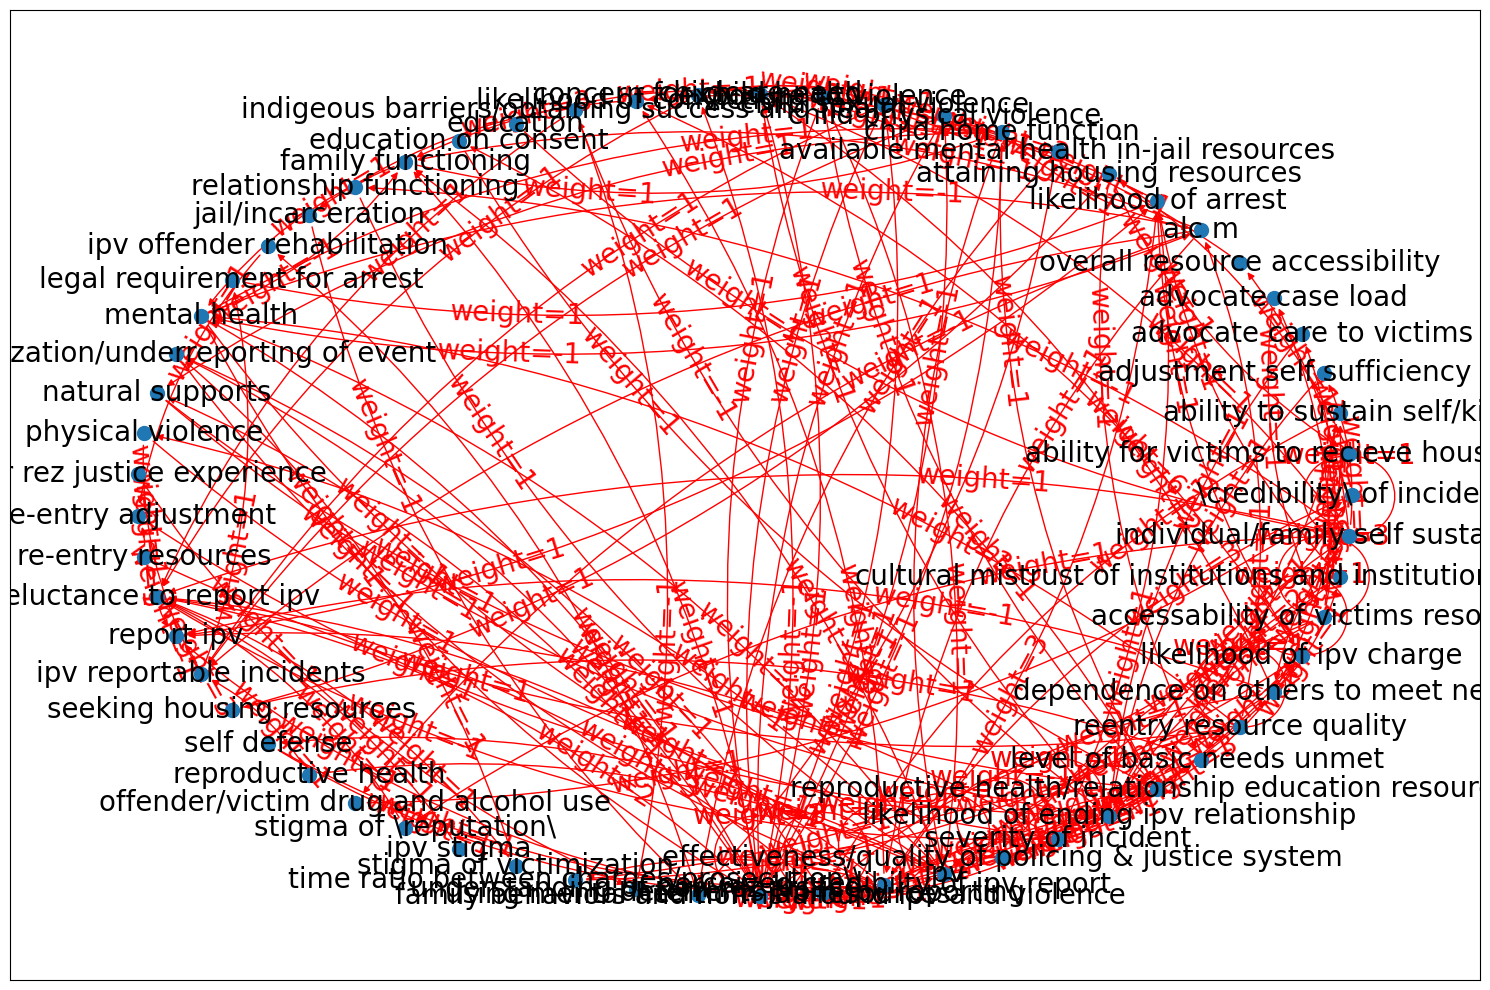

In [79]:
df_subset = merge_df[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)
# print(d)
G_test = nx.MultiDiGraph(d)
# print(dict_var)
cld_nx.draw_labeled_multigraph(G_test, "weight", theme_dict)

In [80]:
adj_mx.head()

to,\credibility\ of incident,ability for victims to recieve housing resources,ability to sustain self/kids,adjustment self sufficiency skills,advocate care to victims,advocate case load,overall resource accessibility,alc m,likelihood of arrest,attaining housing resources,...,severity of incident,likelihood of ending ipv relationship,reproductive health/relationship education resources,level of basic needs unmet,reentry resource quality,dependence on others to meet needs,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,individual/family self sustainment
from,,,,,,,,,,,,,,,,,,,,,
\credibility\ of incident,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ability for victims to recieve housing resources,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
ability to sustain self/kids,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
adjustment self sufficiency skills,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
advocate care to victims,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


## Get an aggregated CLD for one single CLD 

In [81]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['DV justice model clean.json'])

print(df.head(3))

for key, value in list(dict_vars.items())[:3]:
    print(f"{key}: {value}")


   from  to  polarity_type  links
0    13  45              1      1
1    13   9              1      1
2    13  40             -1      1
1: \credibility\ of incident
2: ability for victims to recieve housing resources
3: ability to sustain self/kids


Take "Rapid City Update Themes" Excel Sheet "Clean" column B for Aggregated Variable Name and column E for orignial Variable name

In [82]:
# create a dataframe for the single cld var name and the theme 
vars_cld = pd.DataFrame.from_dict(dict_vars, orient='index').reset_index()
# rename columns 
vars_cld.columns = ['vensim_var_no','var_name']
# turn all the variable names to lowercap 
vars_cld['var_name'] = vars_cld['var_name'].str.lower()
# delete the "" sign 
vars_cld['var_name'] = vars_cld['var_name'].str.replace('"', '')
vars_cld.head(3)

,vensim_var_no,var_name
0,1,\credibility\ of incident
1,2,ability for victims to recieve housing resources
2,3,ability to sustain self/kids


In [83]:
# merge the two dataframes and find the theme name for the cld 
df_aggregate_merge = pd.merge(df_aggregate_names, vars_cld, left_on='variable', right_on='var_name', how='right')
df_aggregate_merge.head(5)

,theme,variable,vensim_var_no,var_name
0,NaN,NaN,1,\credibility\ of incident
1,NaN,NaN,2,ability for victims to recieve housing resources
2,NaN,NaN,3,ability to sustain self/kids
3,NaN,NaN,4,adjustment self sufficiency skills
4,likelihood of ending ipv relationship,adjustment to life reorganization without partner,5,adjustment to life reorganization without partner


In [ ]:
# merging the cld. Count the duplicate themes. 

df_aggregate_merge['vensim_var_no'] = df_aggregate_merge['vensim_var_no'].astype(int)
# create a new variable number for the theme 

list_of_duplicate_themes = parse_cld.get_duplicate_theme_no(df_aggregate_merge)
print(list_of_duplicate_themes)


['family behaviors and norms around ipv and violence', 'deterrents from ipv reporting', 'perceived credibilty of ipv report', 'ipv', 'effectiveness/quality of policing & justice system', 'severity of incident', 'likelihood of ending ipv relationship', 'reproductive health/relationship education resources', 'level of basic needs unmet ', 'reentry resource quality', 'dependence on others to meet needs', 'likelihood of ipv charge', 'accessability of victims resources', 'cultural mistrust of institutions and institutionally provided resources ', 'individual/family self sustainment']


In [ ]:
# create a dictionary where the keys is the orignial var_no and the new var_no is the theme_no

theme_no_dict = {}
for i, val in enumerate(list_of_duplicate_themes):
    theme_no_dict[val] = max(df_aggregate_merge['vensim_var_no']) + i + 1

df_aggregate_merge['theme_no'] = df_aggregate_merge['theme'].map(theme_no_dict)


for i, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme_no']):
        df_aggregate_merge.at[i, 'theme_no'] = row['vensim_var_no']


df_aggregate_merge['theme_no'] = df_aggregate_merge['theme_no'].astype(int)

df_aggregate_merge.head(5)




,theme,variable,vensim_var_no,var_name,theme_no
0,NaN,NaN,1,\credibility\ of incident,1
1,NaN,NaN,2,ability for victims to recieve housing resources,2
2,NaN,NaN,3,ability to sustain self/kids,3
3,NaN,NaN,4,adjustment self sufficiency skills,4
4,likelihood of ending ipv relationship,adjustment to life reorganization without partner,5,adjustment to life reorganization without partner,90


In [ ]:
# create a new dictionary the keys in the vensim vars no, the values is the theme column, if the value is nan, the value is variable 
theme_dict = {}
for index, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme']):
        theme_dict[row['theme_no']] = row['var_name']
    else:
        theme_dict[row['theme_no']] = row['theme']
        
theme_dict = {int(k): v for k, v in theme_dict.items()}


for key, value in list(theme_dict.items())[:3]:
    print(f"{key}: {value}")


1: \credibility\ of incident
2: ability for victims to recieve housing resources
3: ability to sustain self/kids


In [84]:
theme_org_new_dict = dict(zip(df_aggregate_merge['vensim_var_no'], df_aggregate_merge['theme_no']))

new_df = df.copy()
# change all data in df to int 
new_df = new_df.astype(int)
#swap the from column in df to new number based on theme_no_number_dict
new_df['from'] = new_df['from'].map(theme_org_new_dict)
new_df['to'] = new_df['to'].map(theme_org_new_dict)

merge_df = new_df.groupby(['from', 'to']).sum().reset_index()

merge_df.head(5)


KeyError: 'theme_no'

In [ ]:
pol_mx = parse_cld.get_adjacency_matrix(merge_df)

pol_mx.columns = pol_mx.columns.map(theme_dict)
pol_mx.index = pol_mx.index.map(theme_dict)
pol_mx.head(5)

to,\credibility\ of incident,ability for victims to recieve housing resources,ability to sustain self/kids,adjustment self sufficiency skills,advocate care to victims,advocate case load,overall resource accessibility,alc m,likelihood of arrest,attaining housing resources,...,severity of incident,likelihood of ending ipv relationship,reproductive health/relationship education resources,level of basic needs unmet,reentry resource quality,dependence on others to meet needs,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,individual/family self sustainment
from,,,,,,,,,,,,,,,,,,,,,
\credibility\ of incident,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ability for victims to recieve housing resources,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
ability to sustain self/kids,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
adjustment self sufficiency skills,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
advocate care to victims,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [ ]:
# pol_mx.to_csv("aggregate passage_mx.csv")

In [ ]:
df_subset = merge_df[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)

cld_name = 'passage'
g = cld_nx.get_nx_graph(d, theme_dict, unique_theme_names, cld_name)

In [ ]:
# draw graph on gravis
cld_nx.gravis_settings(g)

gv.d3(
    g, 
    graph_height=500,
    edge_curvature=-0.5,
    
    node_size_data_source="degree",
    use_node_size_normalization=True,
    node_size_normalization_min=15,
    node_size_normalization_max=35,
    show_node_label=True,

    many_body_force_strength=-500


 ) 


In [ ]:
cld_nx.cld_nx_properties(g)
cld_nx.cld_nx_edge_properties(g)
cld_nx.cld_nx_node_properties(g)


In [ ]:
cld_nx.draw_labeled_multigraph(g, "weight", theme_dict)

## Combining Matrices 

In [ ]:

matrix1 = [[ 1, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 0]]

matrix1 = pd.DataFrame(matrix1, columns=['a', 'b', 'c', 'd', 'e'])
matrix1.index = rows_1
print(matrix1)



matrix2 = [[ 0, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 1]]

matrix2 = pd.DataFrame(matrix2, columns=['z', 'd', 'c', 'b', 'a'])
matrix2.index = rows_2
print("matrix2")
print(matrix2)

In [ ]:

combined_matrix = parse_cld.get_combine_matrix(matrix1, matrix2)
print(combined_matrix)

In [ ]:
combined_matrix_ = np.where(combined_matrix == 2, 1, combined_matrix)

